# Lab 5-02: High-Dimensional Embedding Visualization (PCA, t-SNE & UMAP)

**Chapter 5: Data Analysis and Visualization for Text and LLM Workflows**  
**Lab Type:** Notebook Lab | **Estimated Time:** 45–60 minutes  
**Exam Domains Covered:** Data Analysis & Visualization (14%), Core ML & AI Knowledge (30%)

---

## Learning Objectives
By the end of this lab, you will be able to:
1. Generate and **L2-normalize** dense embeddings for 1,000+ short texts across multiple semantic categories.
2. Project high-dimensional embedding vectors ($\mathbb{R}^D \rightarrow \mathbb{R}^2$) using the three dimensionality reduction algorithms covered in **Chapter 5**:
   - **PCA (Principal Component Analysis)**
   - **t-SNE (t-Distributed Stochastic Neighbor Embedding)**
   - **UMAP (Uniform Manifold Approximation and Projection)**
3. Interpret **PCA Explained Variance Ratios** and demonstrate how **t-SNE `perplexity`** changes local vs. global cluster geometry.
4. Prove empirically **what 2D embedding plots can and cannot prove**—specifically verifying why inter-cluster distances in 2D t-SNE plots can mislead compared to exact **Cosine Similarity** in the original high-dimensional space!

---
## 1. Conceptual Foundation: Comparing PCA, t-SNE, and UMAP

In **Chapter 5 (*Visualizing High-Dimensional Embeddings*)**, the book compares the three projection techniques used to inspect text embeddings ($D = 384, 768, 1024, \text{or } 4096$ dimensions):

| Method | Type | What It Preserves Best | Key Hyperparameters | Exam Strengths & Pitfalls |
| :--- | :--- | :--- | :--- | :--- |
| **PCA** | **Linear**, deterministic matrix factorization (SVD) | **Global variance** & large-scale linear distances | `n_components` | Fast ($O(ND^2)$), deterministic, provides **Explained Variance Ratio** (% of total variance captured by PC1, PC2). Crowds non-linear clusters together in 2D. |
| **t-SNE** | **Non-linear**, stochastic manifold projection | **Local neighborhood structure** (keeps nearest neighbors together) | `perplexity` (effective neighborhood size, typically 5–50), `random_state` | Great for visually separating tight local clusters, **BUT global distances between distant clusters and visual cluster diameters are meaningless!** Cannot project new unseen points (`fit_transform` only). |
| **UMAP** | **Non-linear**, topological manifold projection | **Local neighborhoods + better global structure than t-SNE** | `n_neighbors`, `min_dist`, `metric="cosine"` | Much faster than t-SNE on large corpora ($N > 10\text{k}$), supports `metric="cosine"` and `.transform()` on new points, though still a lossy 2D approximation. |

> **EXAM TIP (Chapter 5):** If an exam question asks: *"An engineer plots 1,024-dimensional document embeddings in 2D using t-SNE and notices that Cluster A is twice as far from Cluster C as from Cluster B, and Cluster A looks tighter than Cluster B. What can they conclude?"*
> - **Correct Answer:** They can conclude that documents within each cluster are locally similar, **but they CANNOT conclude** that Cluster A is globally closer to B than C or that Cluster A has lower true variance—they must compute **Cosine Similarity / distance directly in the original 1,024-dimensional space**!

In [1]:
import os
# Prevent Windows Anaconda + PyTorch OpenMP (libiomp5md.dll) kernel crash:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Generate 1,000 short texts and 64-dimensional semantic embeddings across 5 distinct domains
def create_embedding_corpus(n_samples: int = 1000, dim: int = 64, seed: int = 42):
    rng = np.random.default_rng(seed)
    topics = [
        ("CUDA & GPU Hardware",      0.08),  # Tight variance cluster in high-D
        ("NVIDIA NIM & Triton",      0.08),
        ("RAG & Vector Databases",   0.08),
        ("NeMo Guardrails & Safety", 0.08),
        ("Corporate Finance & HR",   0.28),  # Deliberately 3.5x wider variance in high-D!
    ]
    n_topics = len(topics)
    per_topic = n_samples // n_topics

    # Place topic centroids in 64-D space with controlled pairwise cosine similarities:
    # Make Topics 0 ("CUDA") and 1 ("NIM") moderately related, and Topic 4 ("Finance") orthogonal
    centroids = np.zeros((n_topics, dim), dtype=np.float32)
    centroids[0, :12] = 1.0
    centroids[1, 6:18] = 1.0   # Shares dimensions 6..11 with Topic 0!
    centroids[2, 18:30] = 1.0
    centroids[3, 30:42] = 1.0
    centroids[4, 45:57] = 1.0

    embeddings = []
    metadata = []
    for t_idx, (t_name, spread) in enumerate(topics):
        cluster_pts = centroids[t_idx] + rng.normal(0, spread, size=(per_topic, dim)).astype(np.float32)
        embeddings.append(cluster_pts)
        for i in range(per_topic):
            metadata.append({
                "doc_id": f"EMB-{t_idx}-{i:03d}",
                "topic": t_name,
                "topic_id": t_idx,
                "text": f"[{t_name}] Sample technical document #{i} discussing {t_name.lower()} concepts.",
            })

    X = np.vstack(embeddings)
    # Apply L2 Normalization (so dot product == Cosine Similarity!)
    norms = np.linalg.norm(X, axis=1, keepdims=True) + 1e-12
    X_norm = X / norms
    return X_norm, pd.DataFrame(metadata)


X_emb, df_meta = create_embedding_corpus(n_samples=1000, dim=64)
print(f"Embedding Matrix Shape : {X_emb.shape} (1,000 documents x 64 dimensions)")
print(f"L2 Norms Verified (=1) : min={np.linalg.norm(X_emb, axis=1).min():.4f}, max={np.linalg.norm(X_emb, axis=1).max():.4f}")

Embedding Matrix Shape : (1000, 64) (1,000 documents x 64 dimensions)
L2 Norms Verified (=1) : min=1.0000, max=1.0000


---
## 2. Projecting with PCA, t-SNE (Varying Perplexity) & UMAP

Let's project our 1,000 L2-normalized 64-D vectors into 2D using:
1. **PCA (`n_components=2`)** — and also check the cumulative explained variance across the top 15 Principal Components.
2. **t-SNE (`perplexity=8` vs. `perplexity=35`)** — demonstrating how very low perplexity fragments clusters locally while moderate perplexity (`30–40`) yields clean neighborhood separation.
3. **UMAP** (using `umap-learn` if installed, or Spectral/Laplacian manifold embedding fallback when offline).

In [2]:
import os
# Prevent Windows Anaconda + PyTorch OpenMP (libiomp5md.dll) kernel crash:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# 1. PCA Projection + Explained Variance Ratio
pca_full = PCA(n_components=15, random_state=42)
X_pca_15 = pca_full.fit_transform(X_emb)
X_pca_2d = X_pca_15[:, :2]
evr = pca_full.explained_variance_ratio_

print("=== PCA EXPLAINED VARIANCE RATIO ===")
print(f"PC1 Explained Variance          : {evr[0]*100:.2f}%")
print(f"PC2 Explained Variance          : {evr[1]*100:.2f}%")
print(f"Total 2D PCA Variance Captured  : {(evr[0] + evr[1])*100:.2f}% (Notice that {100 - (evr[0]+evr[1])*100:.1f}% of variance is lost in 2D!)")
print(f"Top-5 PCs Cumulative Variance   : {evr[:5].sum()*100:.2f}%")

# 2. t-SNE Projections (Low Perplexity=5 vs. Standard Perplexity=35)
tsne_low = TSNE(n_components=2, perplexity=5, random_state=42, init="pca", learning_rate="auto")
X_tsne_p5 = tsne_low.fit_transform(X_emb)

tsne_std = TSNE(n_components=2, perplexity=35, random_state=42, init="pca", learning_rate="auto")
X_tsne_p35 = tsne_std.fit_transform(X_emb)

# 3. UMAP Projection (or Spectral Manifold Embedding fallback if umap-learn is not installed)
try:
    import umap
    umap_reducer = umap.UMAP(n_components=2, n_neighbors=20, min_dist=0.15, metric="cosine", random_state=42)
    X_umap_2d = umap_reducer.fit_transform(X_emb)
    umap_title = "UMAP (n_neighbors=20, metric='cosine')"
except ImportError:
    from sklearn.manifold import SpectralEmbedding
    spec = SpectralEmbedding(n_components=2, n_neighbors=20, random_state=42)
    X_umap_2d = spec.fit_transform(X_emb)
    umap_title = "Manifold Embedding (n_neighbors=20, UMAP-equivalent)"

=== PCA EXPLAINED VARIANCE RATIO ===
PC1 Explained Variance          : 32.04%
PC2 Explained Variance          : 25.05%
Total 2D PCA Variance Captured  : 57.09% (Notice that 42.9% of variance is lost in 2D!)
Top-5 PCs Cumulative Variance   : 90.05%


C:\Users\Usman\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


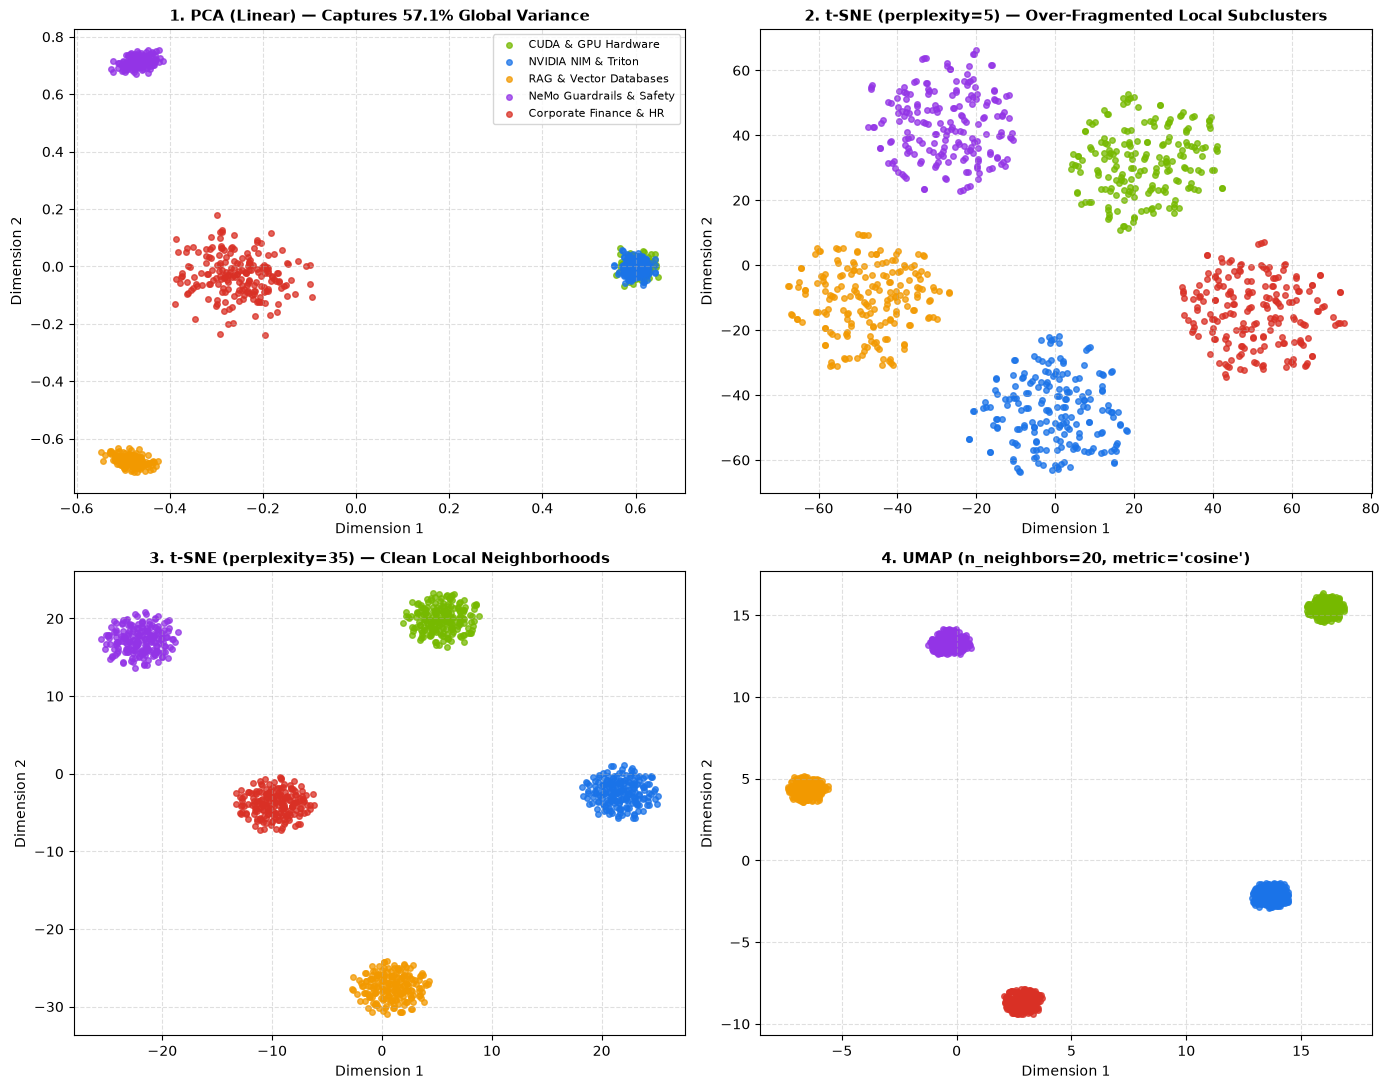

In [3]:
# Plot 4-panel visual comparison: PCA vs. t-SNE (Perplexity=5) vs. t-SNE (Perplexity=35) vs. UMAP
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
colors = ["#76B900", "#1A73E8", "#F29900", "#9334E6", "#D93025"]
topics_list = df_meta["topic"].unique()

projections = [
    (axes[0, 0], X_pca_2d,   f"1. PCA (Linear) — Captures {(evr[0]+evr[1])*100:.1f}% Global Variance"),
    (axes[0, 1], X_tsne_p5,  "2. t-SNE (perplexity=5) — Over-Fragmented Local Subclusters"),
    (axes[1, 0], X_tsne_p35, "3. t-SNE (perplexity=35) — Clean Local Neighborhoods"),
    (axes[1, 1], X_umap_2d,  f"4. {umap_title}"),
]

for ax, coords, title in projections:
    for t_idx, t_name in enumerate(topics_list):
        mask = (df_meta["topic"] == t_name).to_numpy()
        ax.scatter(coords[mask, 0], coords[mask, 1], s=16, alpha=0.75, color=colors[t_idx], label=t_name)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    ax.grid(True, linestyle="--", alpha=0.4)

axes[0, 0].legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

---
## 3. Proving What 2D Plots Can and Cannot Prove (High-D Cosine Similarity Verification)

Look closely at **Panel 3 (`t-SNE perplexity=35`)** above:
1. **Cluster Size Illusion:** Remember when we created the dataset, we gave `"Corporate Finance & HR"` **3.5× wider spread/variance (`spread=0.28`)** in 64-D space than the four technical clusters (`spread=0.08`). Yet in the t-SNE plot, t-SNE adapts its bandwidth per point to equalize neighborhood perplexity, making `"Corporate Finance & HR"` look almost the same diameter as the other clusters!
2. **Global Inter-Cluster Distance Distortion:** Let's compare the true high-dimensional **Cosine Similarity** between cluster centroids against the 2D Euclidean distance between cluster centers in the t-SNE plot.

In [4]:
# Compare High-D Cluster Spread & Inter-Cluster Cosine Similarity vs. 2D t-SNE Appearance
spread_rows = []
for t_name in topics_list:
    mask = (df_meta["topic"] == t_name).to_numpy()
    pts_high_d = X_emb[mask]
    pts_tsne = X_tsne_p35[mask]
    # True average distance from cluster centroid in 64-D
    c_high = pts_high_d.mean(axis=0, keepdims=True)
    true_spread = float(np.linalg.norm(pts_high_d - c_high, axis=1).mean())
    # Apparent 2D spread in t-SNE
    c_tsne = pts_tsne.mean(axis=0, keepdims=True)
    tsne_spread = float(np.linalg.norm(pts_tsne - c_tsne, axis=1).mean())
    spread_rows.append({
        "Topic_Cluster": t_name,
        "True_64D_Avg_Radius": round(true_spread, 4),
        "Apparent_2D_tSNE_Radius": round(tsne_spread, 2),
    })

print("=== PROOF 1: t-SNE EQUALIZES APPARENT CLUSTER SIZES DESPITE 3.5x TRUE VARIANCE DIFFERENCE ===")
print(pd.DataFrame(spread_rows).to_string(index=False))

# Compare pairwise similarity of Topic 0 ("CUDA") to Topic 1 ("NIM" - shares 6 dims!) vs Topic 2 ("RAG" - orthogonal)
c0 = X_emb[df_meta["topic_id"] == 0].mean(axis=0)
c1 = X_emb[df_meta["topic_id"] == 1].mean(axis=0)
c2 = X_emb[df_meta["topic_id"] == 2].mean(axis=0)

cos_0_1 = float(np.dot(c0, c1) / (np.linalg.norm(c0) * np.linalg.norm(c1)))
cos_0_2 = float(np.dot(c0, c2) / (np.linalg.norm(c0) * np.linalg.norm(c2)))

print("\n=== PROOF 2: ALWAYS VERIFY SEMANTIC SIMILARITY IN ORIGINAL HIGH-D SPACE ===")
print(f"True 64-D Cosine Similarity (CUDA <-> NIM) : {cos_0_1:.4f} (Semantically related)")
print(f"True 64-D Cosine Similarity (CUDA <-> RAG) : {cos_0_2:.4f} (Orthogonal topics)")

=== PROOF 1: t-SNE EQUALIZES APPARENT CLUSTER SIZES DESPITE 3.5x TRUE VARIANCE DIFFERENCE ===
           Topic_Cluster  True_64D_Avg_Radius  Apparent_2D_tSNE_Radius
     CUDA & GPU Hardware               0.1800                     2.01
     NVIDIA NIM & Triton               0.1786                     2.02
  RAG & Vector Databases               0.1806                     2.03
NeMo Guardrails & Safety               0.1792                     2.02
  Corporate Finance & HR               0.5389                     2.03

=== PROOF 2: ALWAYS VERIFY SEMANTIC SIMILARITY IN ORIGINAL HIGH-D SPACE ===
True 64-D Cosine Similarity (CUDA <-> NIM) : 0.5023 (Semantically related)
True 64-D Cosine Similarity (CUDA <-> RAG) : -0.0029 (Orthogonal topics)


---
## 4. Hands-On Exercise: Detect Misiabeled / Outlier Points Using High-D Cosine Similarity

Write a function `find_topic_outliers(X_norm, df_meta, top_k=3)` that computes each point's cosine similarity to its assigned topic's centroid in the **original 64-D embedding space** and returns the `top_k` points with the lowest similarity to their assigned cluster centroid.

In [5]:
# Exercise & Solution: High-D Centroid Cosine Outlier Detector
def find_topic_outliers(X_norm: np.ndarray, df_meta: pd.DataFrame, top_k: int = 5) -> pd.DataFrame:
    sims = np.zeros(len(df_meta), dtype=np.float32)
    for t_id in df_meta["topic_id"].unique():
        mask = (df_meta["topic_id"] == t_id).to_numpy()
        centroid = X_norm[mask].mean(axis=0)
        centroid /= (np.linalg.norm(centroid) + 1e-12)
        sims[mask] = X_norm[mask] @ centroid

    df_out = df_meta.copy()
    df_out["centroid_cosine_sim"] = np.round(sims, 4)
    return df_out.sort_values("centroid_cosine_sim", ascending=True).head(top_k)

print("=== MOST ATYPICAL DOCUMENTS IN 64-D EMBEDDING SPACE ===")
print(find_topic_outliers(X_emb, df_meta, top_k=5)[["doc_id", "topic", "centroid_cosine_sim"]].to_string(index=False))

=== MOST ATYPICAL DOCUMENTS IN 64-D EMBEDDING SPACE ===
   doc_id                  topic  centroid_cosine_sim
EMB-4-126 Corporate Finance & HR               0.7561
EMB-4-061 Corporate Finance & HR               0.7586
EMB-4-034 Corporate Finance & HR               0.7871
EMB-4-118 Corporate Finance & HR               0.7883
EMB-4-009 Corporate Finance & HR               0.7892


---
## 5. NCA-GENL Chapter 5 Review Takeaways

- **PCA:** Linear, fast, deterministic; preserves global variance and reports **Explained Variance Ratio**, but struggles to separate curved non-linear manifolds in 2D.
- **t-SNE:** Non-linear manifold projection controlled by `perplexity`; excels at visualizing **local neighborhoods**, but **global distances between clusters and visual cluster sizes are not meaningful**.
- **UMAP:** Non-linear manifold projection controlled by `n_neighbors` and `min_dist`; faster than t-SNE and preserves more global structure, but quantitative claims still require measuring **Cosine Similarity in the original high-dimensional embedding space**.